In [1]:
import scanpy as sc
import anndata as ad

import pandas as pd
import numpy as np
from scipy import ndimage
#import geopandas as gpd

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib
from   matplotlib import colors
from matplotlib.lines import Line2D

from pandas.api.types import CategoricalDtype

import os

import seaborn as sns

In [2]:
#### Set plotting parameters
matplotlib.rcParams.update({
    "font.family":        "Liberation Sans",
    "pdf.fonttype":       42,   # TrueType → keeps glyphs grouped in Illustrator
    "ps.fonttype":        42,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.25,
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.minor.width":  0.5,
    "ytick.minor.width":  0.5,
    "xtick.major.size":   3.5,
    "ytick.major.size":   3.5,
    "axes.labelsize":     6,
    "xtick.labelsize":    6,
    "ytick.labelsize":    6,
    "legend.fontsize":    5,
    "axes.titlesize":     7,
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.transparent": False,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.05,
})

### inches to points conversion
MM = 1 / 25.4

In [3]:

from feature_significance_updated import (test_feature_significance, summarise_significant_features, 
                                  plot_feature_significance,plot_annotated_heatmap,plot_updown_bars,
                                  plot_top_features,plot_selected_features)

from dna_loci_significance import correct_by_normals_loci

___
### Read and normalize data

In [4]:
# ── File paths — edit these ───────────────────────────────────────────────────
ADATA_PATH      = 'seqFISH_discovery_cohort.h5ad'                       # AnnData object
DNA_MAT_PATH    = 'DNA_counts_filtered_rolled_annotated.csv'  # cell by DNA counts 
LOCI_PATH       = 'DNA_loci_orderd.csv'                 # loci → chromosome/arm mapping

OUT_DIR = 'figures'
os.makedirs(OUT_DIR, exist_ok=True)

print('Paths configured.')

Paths configured.


In [5]:
#Read RNA data
rna_obj = sc.read_h5ad(ADATA_PATH)
rna_obj

print(rna_obj.obs['sample_group'].unique())
print(len(rna_obj.obs['patient'].unique()), 'patients')
print(len(rna_obj.obs['ROI'].unique()), 'samples')
rna_obj

['GBM', 'future MT', 'Transformed', 'future stable | Rec', 'future stable | Init', 'Gliosarcoma']
Categories (6, object): ['GBM', 'Gliosarcoma', 'Transformed', 'future MT', 'future stable | Init', 'future stable | Rec']
23 patients
42 samples


AnnData object with n_obs × n_vars = 693013 × 1150
    obs: 'orig.ident', 'cell_area', 'center_x', 'center_y', 'patient', 'gender', 'grade', 'histology', 'IDH', 'cell_type', 'ROI', 'cellID', 'patient_id', 'state', 'sample_group', 'class'
    var: 'gene_names', 'gene_ids'
    uns: 'build'
    obsm: 'spatial'
    layers: 'counts'

In [6]:
#Read DNA data
dna_data   = pd.read_csv(DNA_MAT_PATH, index_col=0, dtype={'ROI':str})
loci_df    = pd.read_csv(LOCI_PATH)
print(len(dna_data['ROI'].unique()), 'samples')
dna_data.head(2)

30 samples


,block1.bin1,block1.bin2,block1.bin3,block1.bin4,block1.bin5,block1.bin6,block1.bin7,block1.bin8,block1.bin9,block1.bin10,...,block68.bin4,block68.bin5,cell_id,Malignant_status,ROI,cell_type,histology,center_x,center_y,sample_group
0,2.22,1.66,2.66,3.99,5.33,5.33,5.33,3.99,3.99,3.99,...,0.0,0.0,23_23,Normal,2122,Olig. normal,Oligo,3742.67,181.16,future MT
1,0.00,0.00,0.00,0.00,0.99,1.98,1.98,1.98,2.98,3.97,...,0.0,0.0,25_23,Normal,2122,Olig. normal,Oligo,1683.57,180.95,future MT


In [ ]:
#Read contact and loci data
loci_c = pd.read_csv('DNA_arm_level_loci_fractions_corrected.csv', index_col=0, dtype={'sample_id' : str})
print(loci_c.head(2))

contacts_c = pd.read_csv('DNA_contact_features_corrected.csv', index_col=0, dtype={'ROI' : str})
print(contacts_c.head(2))

In [8]:
# ── correct binblock loci ─────────────────────────────────────────────────────────────
print("\nRunning corrections (binblock loci...)")
meta_cols         = ["ROI", "cell_type", "histology","Malignant_status","cell_id", "center_x",	"center_y", "sample_group"]
method = 'zscore'
normal_cell_types = ['Olig. normal', 'Microglia']
alpha=0.05

corrected_loci = correct_by_normals_loci(
    dna_data, #na_data,
    id_col = 'ROI',
    method=method,
    normal_cell_types=normal_cell_types,
    meta_cols=meta_cols,
)


Running corrections (binblock loci...)
  Correction done [zscore]. Null = 0.0. 30/30 samples corrected.


___
#### Remove sample 4668 since it has <500 cells in the dna data and <90 malignant cells

In [9]:
#make colnames the same
loci_c.rename(columns={'sample_id':'ROI'}, inplace=True)

In [10]:
corrected_loci   = corrected_loci.loc[~corrected_loci['ROI'].isin(['4668']),]
contacts_c       = contacts_c.loc[~contacts_c['ROI'].isin(['4668']),]
loci_c           = loci_c.loc[~loci_c['ROI'].isin(['4668']),]

print(corrected_loci['ROI'].unique())
print(contacts_c['ROI'].unique())
print(loci_c['ROI'].unique())

['2122' '2543' '2683' '2789' '2830' '3097_1' '3209' '3364' '3557' '3754'
 '3825' '3883' '4250' '4494_1' '4494_2' '4523' '4555' '4590' '4904' '4970'
 '5121' '5201' '5272_1' '5272_2' '5538_1' '5538_2' '5541_1' '5541_2'
 '5597']
['2122' '2543' '2683' '2789' '2830' '3097' '3097_1' '3209' '3364' '3557'
 '3754' '3825' '3883' '4250' '4477' '4494_1' '4494_2' '4523' '4555' '4590'
 '4904' '4970' '5121' '5201' '5272_1' '5272_2' '5538_1' '5538_2' '5541_1'
 '5541_2' '5597']
['2122' '2543' '2683' '2789' '2830' '3097' '3097_1' '3209' '3364' '3557'
 '3703' '3754' '3825' '3883' '4250' '4477' '4494_1' '4494_2' '4523' '4555'
 '4590' '4904' '4970' '5121' '5201' '5272_1' '5272_2' '5538_1' '5538_2'
 '5541_1' '5541_2' '5597']


___
### Calculate PCA

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [12]:
state_map = dict(zip(rna_obj.obs['ROI'],rna_obj.obs['sample_group']))

#add state
corrected_loci['state'] = corrected_loci['ROI'].map(state_map)
print(corrected_loci['state'].unique())

contacts_c['state'] = contacts_c['ROI'].map(state_map)
loci_c['state'] = loci_c['ROI'].map(state_map)
print(contacts_c['state'].unique())
print(loci_c['state'].unique())


['future MT' 'Transformed' 'GBM' 'future stable | Init'
 'future stable | Rec']
['future MT' 'Transformed' nan 'GBM' 'future stable | Init'
 'future stable | Rec' 'Gliosarcoma']
['future MT' 'Transformed' nan 'GBM' 'future stable | Init'
 'future stable | Rec' 'Gliosarcoma']


/tmp/ipykernel_208441/1303057915.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  corrected_loci['state'] = corrected_loci['ROI'].map(state_map)


In [13]:
### PCA on CNA 
cancer_groups = ['future stable | Init','future MT','future stable | Rec','Transformed']

cnv_col  = loci_df['blockbin']
cnv_col  = cnv_col.str.replace('_','.')

mask_cnv = corrected_loci['state'].isin(cancer_groups) & corrected_loci['cell_type'].isin(['OPC','AC.like','OPC.like Prolif.'])

print(corrected_loci.loc[mask_cnv,'state'].unique())
print(corrected_loci.loc[mask_cnv,'ROI'].unique())
print(corrected_loci.loc[mask_cnv, 'cell_type'].unique())

cnv_means = {}

for sid, grp in corrected_loci.loc[mask_cnv,].groupby(['state','ROI']):
    cnv_means[sid[1]] = grp[cnv_col].mean()

cnv_means = pd.DataFrame(cnv_means).T
cnv_means.head(2)

['future MT' 'Transformed' 'future stable | Init' 'future stable | Rec']
['2122' '2543' '2683' '2789' '2830' '3209' '3364' '3557' '3754' '3825'
 '4250' '4494_1' '4494_2' '4523' '4555' '4590' '4904' '4970' '5121' '5201'
 '5272_1' '5272_2' '5538_1' '5538_2' '5541_1' '5541_2']
['OPC' 'AC.like' 'OPC.like Prolif.']


,block1.bin1,block1.bin2,block1.bin3,block1.bin4,block1.bin5,block1.bin6,block1.bin7,block1.bin8,block1.bin9,block1.bin10,...,block67.bin10,block67.bin11,block67.bin13,block67.bin14,block67.bin15,block68.bin1,block68.bin2,block68.bin3,block68.bin4,block68.bin5
2543,-0.322464,-0.317750,-0.321120,-0.285609,-0.295365,-0.268012,-0.314301,-0.319947,-0.33004,-0.323840,...,-0.005220,-0.021884,-0.019219,-0.037085,-0.015097,-0.011694,-0.001984,0.001135,0.011491,0.001370
3825,0.057684,0.049292,0.040577,0.027270,0.013543,0.007535,0.011027,0.010511,0.01818,0.027754,...,-0.021991,-0.023761,-0.018013,-0.029201,-0.031741,-0.018986,-0.009164,-0.014857,-0.007678,-0.000889


In [14]:
# run PCA
pca_cnv   = PCA(n_components=2)
X_pca_cnv = pca_cnv.fit_transform(cnv_means)
X_pca_cnv = pd.DataFrame(X_pca_cnv, index=cnv_means.index, columns=['PC1', 'PC2'])

sample_group_map = rna_obj.obs[['ROI', 'histology','sample_group']].drop_duplicates().set_index('ROI')

X_pca_cnv = X_pca_cnv.merge(sample_group_map, left_index=True, right_index=True, how='left')
X_pca_cnv['histology'] = X_pca_cnv['histology'].astype(str) 
X_pca_cnv['sample_group'] = X_pca_cnv['sample_group'].astype(str) 

In [15]:
### PCA on contacts

contact_col = list(contacts_c.columns.drop(['ROI', 'cell_id','class', 'total_loci', 'cell_type','state']))
loci_col    = list(loci_c.columns.drop(['ROI', 'cell_id', 'class', 'total_loci', 'cell_type','state']))

mask_contacts = contacts_c['state'].isin(cancer_groups) & contacts_c['cell_type'].isin(['OPC','AC.like','OPC.like Prolif.'])

mask_loci = loci_c['state'].isin(cancer_groups) & loci_c['cell_type'].isin(['OPC','AC.like','OPC.like Prolif.'])

print(contacts_c.loc[mask_contacts,'state'].unique())
print(contacts_c.loc[mask_contacts,'ROI'].unique())
print(contacts_c.loc[mask_contacts, 'cell_type'].unique())

contact_means = {}
loci_means    = {}

for sid, grp in contacts_c.loc[mask_contacts,].groupby(['state','ROI']):
    contact_means[sid[1]] = grp[contact_col].mean()

for sid, grp in loci_c.loc[mask_loci,].groupby(['state','ROI']):
    loci_means[sid[1]] = grp[loci_col].mean()

contact_means = pd.DataFrame(contact_means).T
loci_means    = pd.DataFrame(loci_means).T

loci_means.head(2)

['future MT' 'Transformed' 'future stable | Init' 'future stable | Rec']
['2122' '2543' '2683' '2789' '2830' '3209' '3364' '3557' '3754' '3825'
 '4250' '4494_1' '4494_2' '4523' '4555' '4590' '4904' '4970' '5121' '5201'
 '5272_1' '5272_2' '5538_1' '5538_2' '5541_1' '5541_2']
['OPC' 'AC.like' 'OPC.like Prolif.']


,loci_frac_chr10_p,loci_frac_chr10_q,loci_frac_chr11_p,loci_frac_chr11_q,loci_frac_chr12_p,loci_frac_chr12_q,loci_frac_chr13_q,loci_frac_chr14_q,loci_frac_chr15_q,loci_frac_chr16_p,...,loci_frac_chr6_p,loci_frac_chr6_q,loci_frac_chr7_p,loci_frac_chr7_q,loci_frac_chr8_p,loci_frac_chr8_q,loci_frac_chr9_p,loci_frac_chr9_q,loci_frac_chrX_p,loci_frac_chrX_q
2543,0.033468,0.060396,0.006022,0.064575,0.027817,0.034510,-0.019374,0.042919,-0.008136,0.159484,...,0.156016,0.013044,0.020818,-0.038124,-0.453266,-0.026799,-0.479537,0.652773,-0.024912,-0.022670
3825,0.065161,-0.000916,-0.024285,0.078926,0.027215,-0.100522,0.105046,-0.018342,0.083460,0.101114,...,-0.033214,0.003756,0.075766,0.296436,0.185525,0.007939,-0.152591,0.058677,-0.224649,-0.041043


In [16]:
# run PCA
pca_contacts   = PCA(n_components=2)
X_pca_contacts = pca_contacts.fit_transform(contact_means)
X_pca_contacts = pd.DataFrame(X_pca_contacts, index=contact_means.index, columns=['PC1', 'PC2'])

pca_loci   = PCA(n_components=2)
X_pca_loci = pca_loci.fit_transform(loci_means)
X_pca_loci = pd.DataFrame(X_pca_loci, index=loci_means.index, columns=['PC1', 'PC2'])

X_pca_contacts = X_pca_contacts.merge(sample_group_map, left_index=True, right_index=True, how='left')
X_pca_loci = X_pca_loci.merge(sample_group_map, left_index=True, right_index=True, how='left')

#make category col into str
X_pca_contacts['histology'] = X_pca_contacts['histology'].astype(str) 
X_pca_contacts['sample_group'] = X_pca_contacts['sample_group'].astype(str) 
X_pca_loci['histology'] = X_pca_loci['histology'].astype(str) 
X_pca_loci['sample_group'] = X_pca_loci['sample_group'].astype(str) 

### Plot PCA

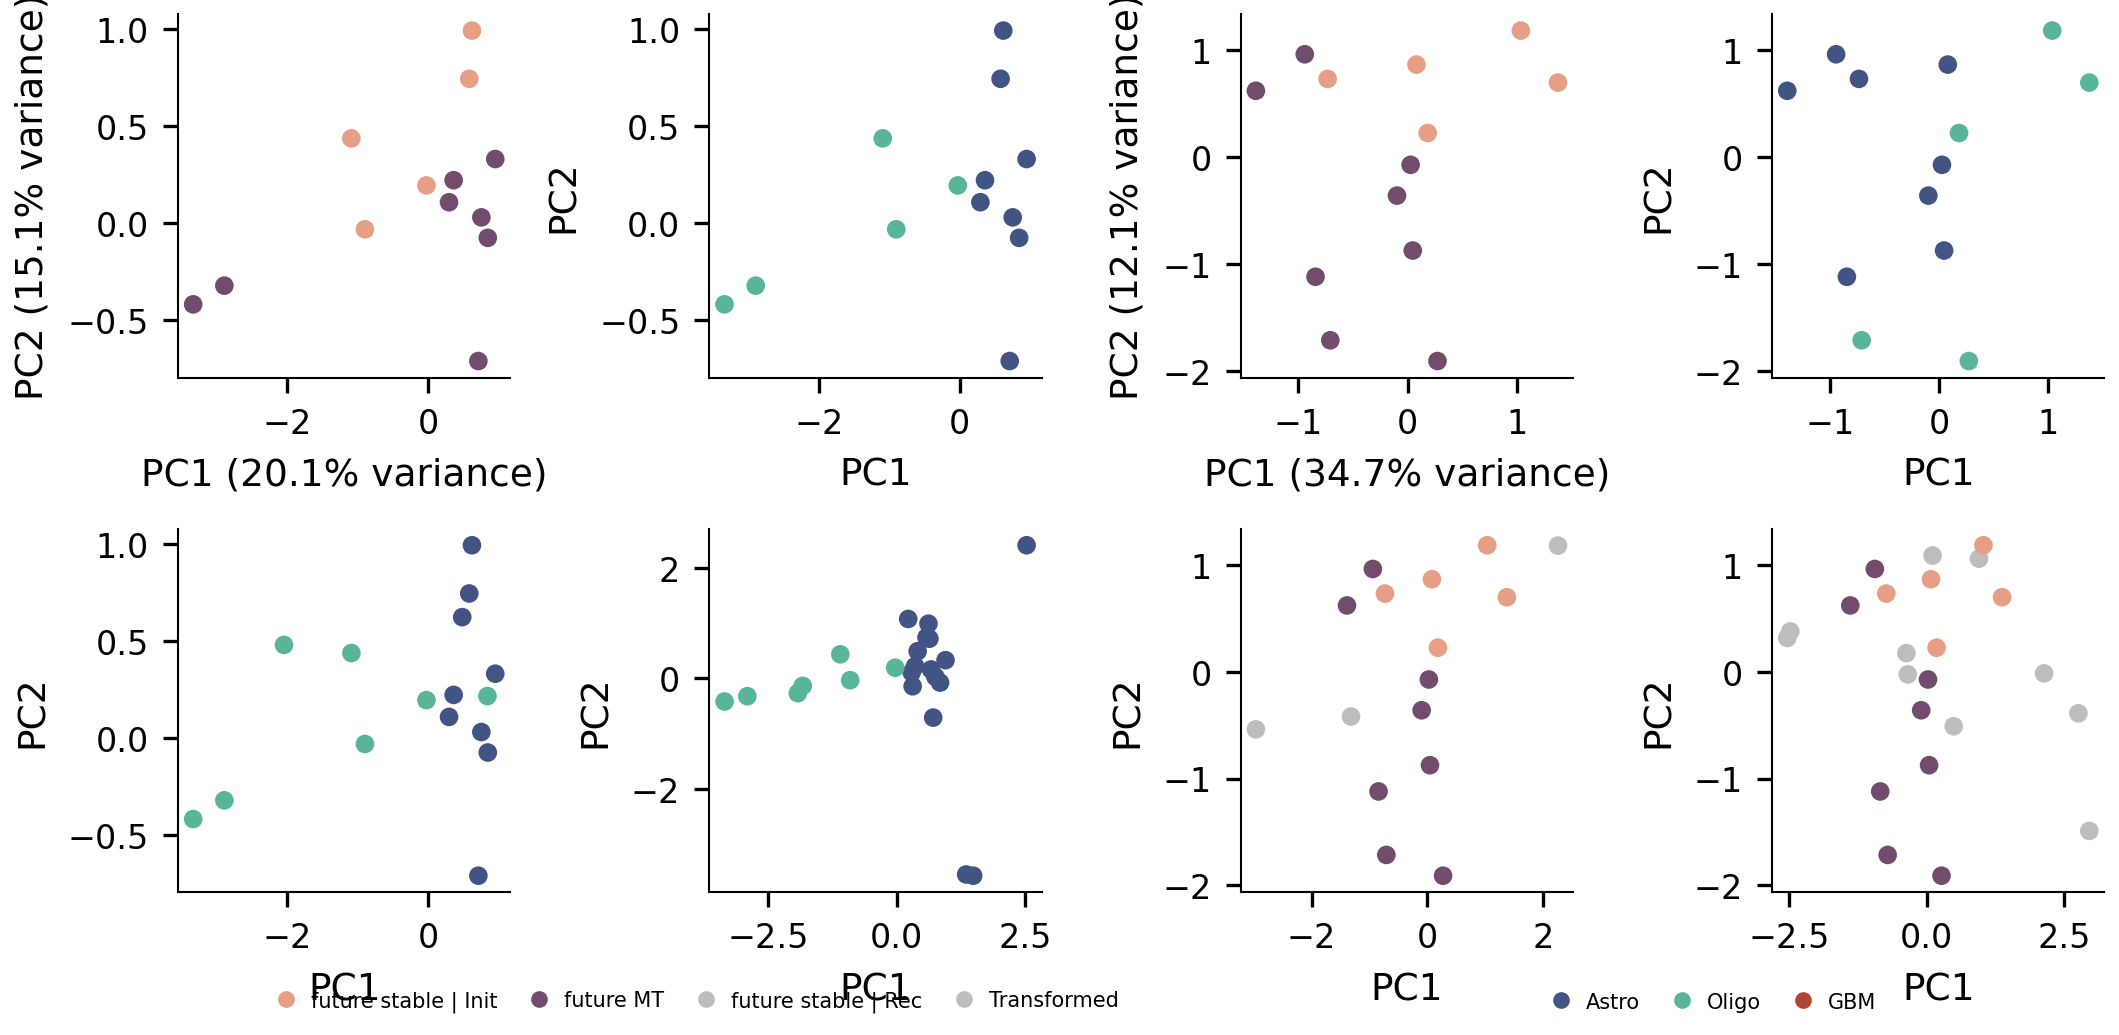

In [17]:
sample_group_colors = {
    'future stable | Init': '#E69E84',
    'future MT':            '#724C6D',
    'future stable | Rec':  '#bdbdbd',
    'Transformed':          '#bdbdbd',   # note: same green as 'stable | Rec'
}
cancer_colors = {
    'Astro': '#415483',
    'Oligo': '#59B599',
    'GBM':   '#B04534',
}

pt_size = 20

fig, axs = plt.subplots(2, 4, figsize=(MM*183, MM*90))

# shared scatter kwargs: no per-panel legend, no marker edges (cleaner at tiny
# sizes), rasterized points keep the file light when editing in Illustrator
sc_kw = dict(s=pt_size, legend=False, edgecolor='none', linewidth=0)

# --- top row: Init + MT only ---
mask = X_pca_cnv['sample_group'].isin(['future stable | Init', 'future MT'])
sns.scatterplot(X_pca_cnv[mask], x='PC1', y='PC2', hue='sample_group',
                palette=sample_group_colors, ax=axs[0, 0], **sc_kw)
axs[0, 0].set_xlabel(f"PC1 ({pca_cnv.explained_variance_ratio_[0]:.1%} variance)")
axs[0, 0].set_ylabel(f"PC2 ({pca_cnv.explained_variance_ratio_[1]:.1%} variance)")

sns.scatterplot(X_pca_cnv[mask], x='PC1', y='PC2', hue='histology',
                palette=cancer_colors, ax=axs[0, 1], **sc_kw)

mask = X_pca_contacts['sample_group'].isin(['future stable | Init', 'future MT'])
sns.scatterplot(X_pca_contacts[mask], x='PC1', y='PC2', hue='sample_group',
                palette=sample_group_colors, ax=axs[0, 2], **sc_kw)
axs[0, 2].set_xlabel(f"PC1 ({pca_contacts.explained_variance_ratio_[0]:.1%} variance)")
axs[0, 2].set_ylabel(f"PC2 ({pca_contacts.explained_variance_ratio_[1]:.1%} variance)")

sns.scatterplot(X_pca_contacts[mask], x='PC1', y='PC2', hue='histology',
                palette=cancer_colors, ax=axs[0, 3], **sc_kw)

# --- bottom row: add recurrent samples ---
# cnv, stable | Rec
mask = X_pca_cnv['sample_group'].isin(['future stable | Init', 'future MT', 'future stable | Rec'])
sns.scatterplot(X_pca_cnv[mask], x='PC1', y='PC2', hue='histology',#sample_group',
                palette=cancer_colors, ax=axs[1, 0], **sc_kw)

# cnv, Transformed
mask = X_pca_cnv['sample_group'].isin(['future stable | Init', 'future MT', 'Transformed'])
sns.scatterplot(X_pca_cnv[mask], x='PC1', y='PC2', hue='histology',#sample_group',
                palette=cancer_colors, ax=axs[1, 1], **sc_kw)

# contacts, stable | Rec
mask = X_pca_contacts['sample_group'].isin(['future stable | Init', 'future MT', 'future stable | Rec'])
sns.scatterplot(X_pca_contacts[mask], x='PC1', y='PC2', hue='sample_group',
                palette=sample_group_colors, ax=axs[1, 2], **sc_kw)

# contacts, Transformed
mask = X_pca_contacts['sample_group'].isin(['future stable | Init', 'future MT', 'Transformed'])
sns.scatterplot(X_pca_contacts[mask], x='PC1', y='PC2', hue='sample_group',
                palette=sample_group_colors, ax=axs[1, 3], **sc_kw)

# --- single shared legend, built manually so it never depends on which panel ---
def _dot(color, label):
    return Line2D([0], [0], marker='o', linestyle='', markersize=4,
                  markerfacecolor=color, markeredgecolor='none', label=label)

state_handles  = [_dot(c, l) for l, c in sample_group_colors.items()]
cancer_handles = [_dot(c, l) for l, c in cancer_colors.items()]

fig.tight_layout()
fig.subplots_adjust(bottom=0.14)   # reserve room for the legends

fig.legend(handles=state_handles,  loc='lower center', bbox_to_anchor=(0.33, 0.01),
           ncol=4, frameon=False, handletextpad=0.2, columnspacing=1.0)
fig.legend(handles=cancer_handles, loc='lower center', bbox_to_anchor=(0.80, 0.01),
           ncol=3, frameon=False, handletextpad=0.2, columnspacing=1.0)

plt.savefig(f'{OUT_DIR}/fig3_PCA_all.pdf')


___
### Find significant features

In [18]:
feat_groups = {}
feat_groups['contacts_corr'] = contact_col
feat_groups['loci_frac'] = []

In [20]:
# ── significance testing ──────────────────────────────────────────
alpha=0.05

cancer_groups = ['future stable | Init','future MT','Transformed']
print(f"Cancer groups found: {cancer_groups}")


print("\nStep 1: testing feature significance...")
results = test_feature_significance(
    df_original       = contacts_c,
    loci_corrected    = loci_c,
    contacts_corrected= contacts_c,
    feat_groups       = feat_groups,
    method            = method,
    cancer_groups     = cancer_groups,
    alpha             = alpha,
    test_vs_null      = True,
    test_between_groups=True,
    group_col = 'state',
    id_col    = 'ROI'
)
summary = summarise_significant_features(results, cancer_groups)

Cancer groups found: ['future stable | Init', 'future MT', 'Transformed']

Step 1: testing feature significance...

Test 1: each group vs null (0.0) [one-sample t-test, BH correction per group]
  226 significant feature × group combinations (FDR < 0.05)

Test 2: restricted to 213 features significant in Test 1 (out of 861 total)
  3 pair(s), two-sample Welch t-test, BH correction per pair
  78 significant feature × pair combinations (FDR < 0.05)

── Test 1: significant features vs null ──────────────────────────
Cancer group              Feature type     Direction    N features
─────────────────────────────────────────────────────────────────
Transformed               TOTAL            —                    15
Transformed               contacts_corr    depleted             15
future MT                 TOTAL            —                   211
future MT                 contacts_corr    depleted            108
future MT                 contacts_corr    elevated            103

── Test 2: fe

#### Plot

Saved: figures/Fig3_representative_contact_feats.pdf


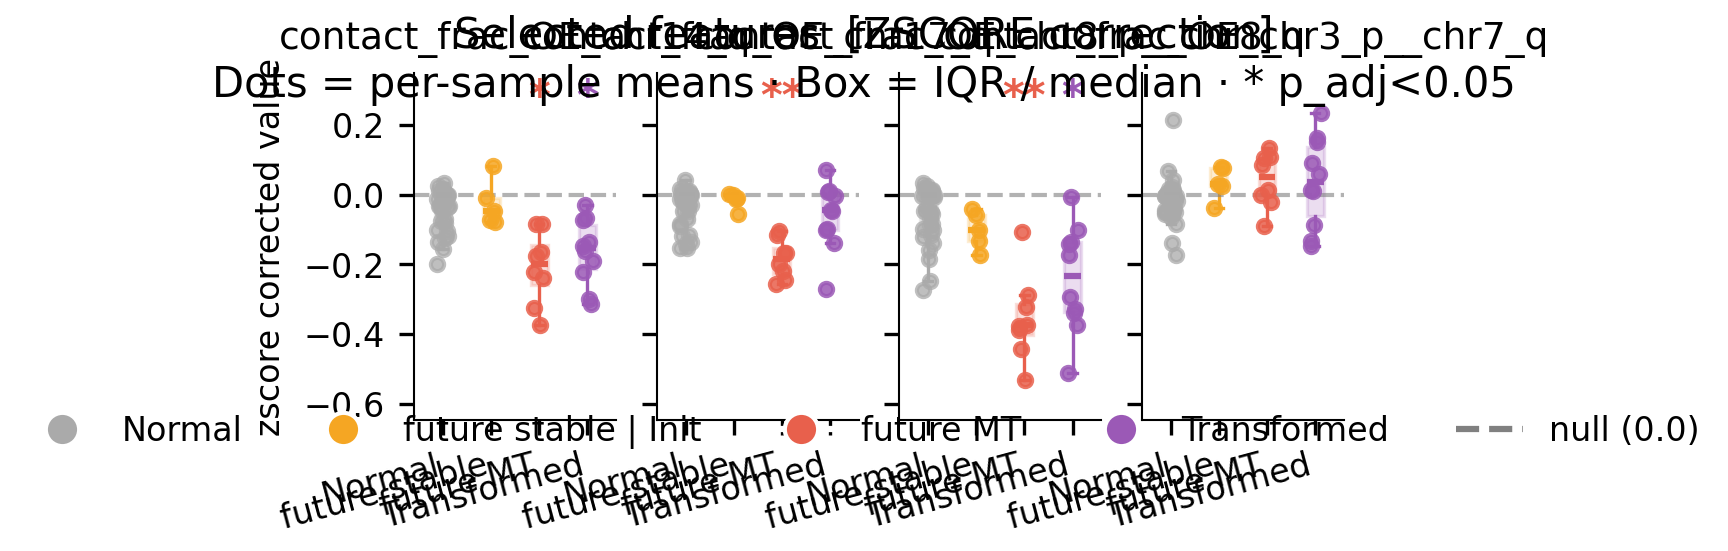

In [21]:
between = results['between_groups']
vs_null = results['vs_null']

loci_feats_vs_null = vs_null.loc[vs_null['significant'] & vs_null['feat_type'].isin(['loci_frac']),'feature']
loci_feats_between = between.loc[between['significant'] & between['feat_type'].isin(['loci_frac']),'feature']

contact_feats = ['contact_frac_OE_chr14_q','contact_frac_OE_chr17_q','contact_frac_OE_chr8_p__chr8_q','contact_frac_OE_chr3_p__chr7_q']

fig = plot_selected_features(
    features           = contact_feats,#list(loci_feats_vs_null),
    results            = results['vs_null'],   # pass None to skip significance stars
    df_original        = contacts_c,
    loci_corrected     = loci_c,
    contacts_corrected = contacts_c,
    feat_groups        = feat_groups,
    cancer_groups      = ['future stable | Init','future MT','Transformed'],
    group_order        = ['future stable | Init','future MT','Transformed'],
    method             = "zscore",
    out_path           = f'{OUT_DIR}/Fig3_representative_contact_feats.pdf',
)

77
Main panel types:  ['future stable | Init', 'future MT']
Extra panel types: ['Transformed', 'future stable | Rec']
Main matrix:  13 rows × 77 features
Extra matrix: 13 rows × 77 features
Saved: figures/Fig3_top_feature_heatmap_MT_noMT.pdf


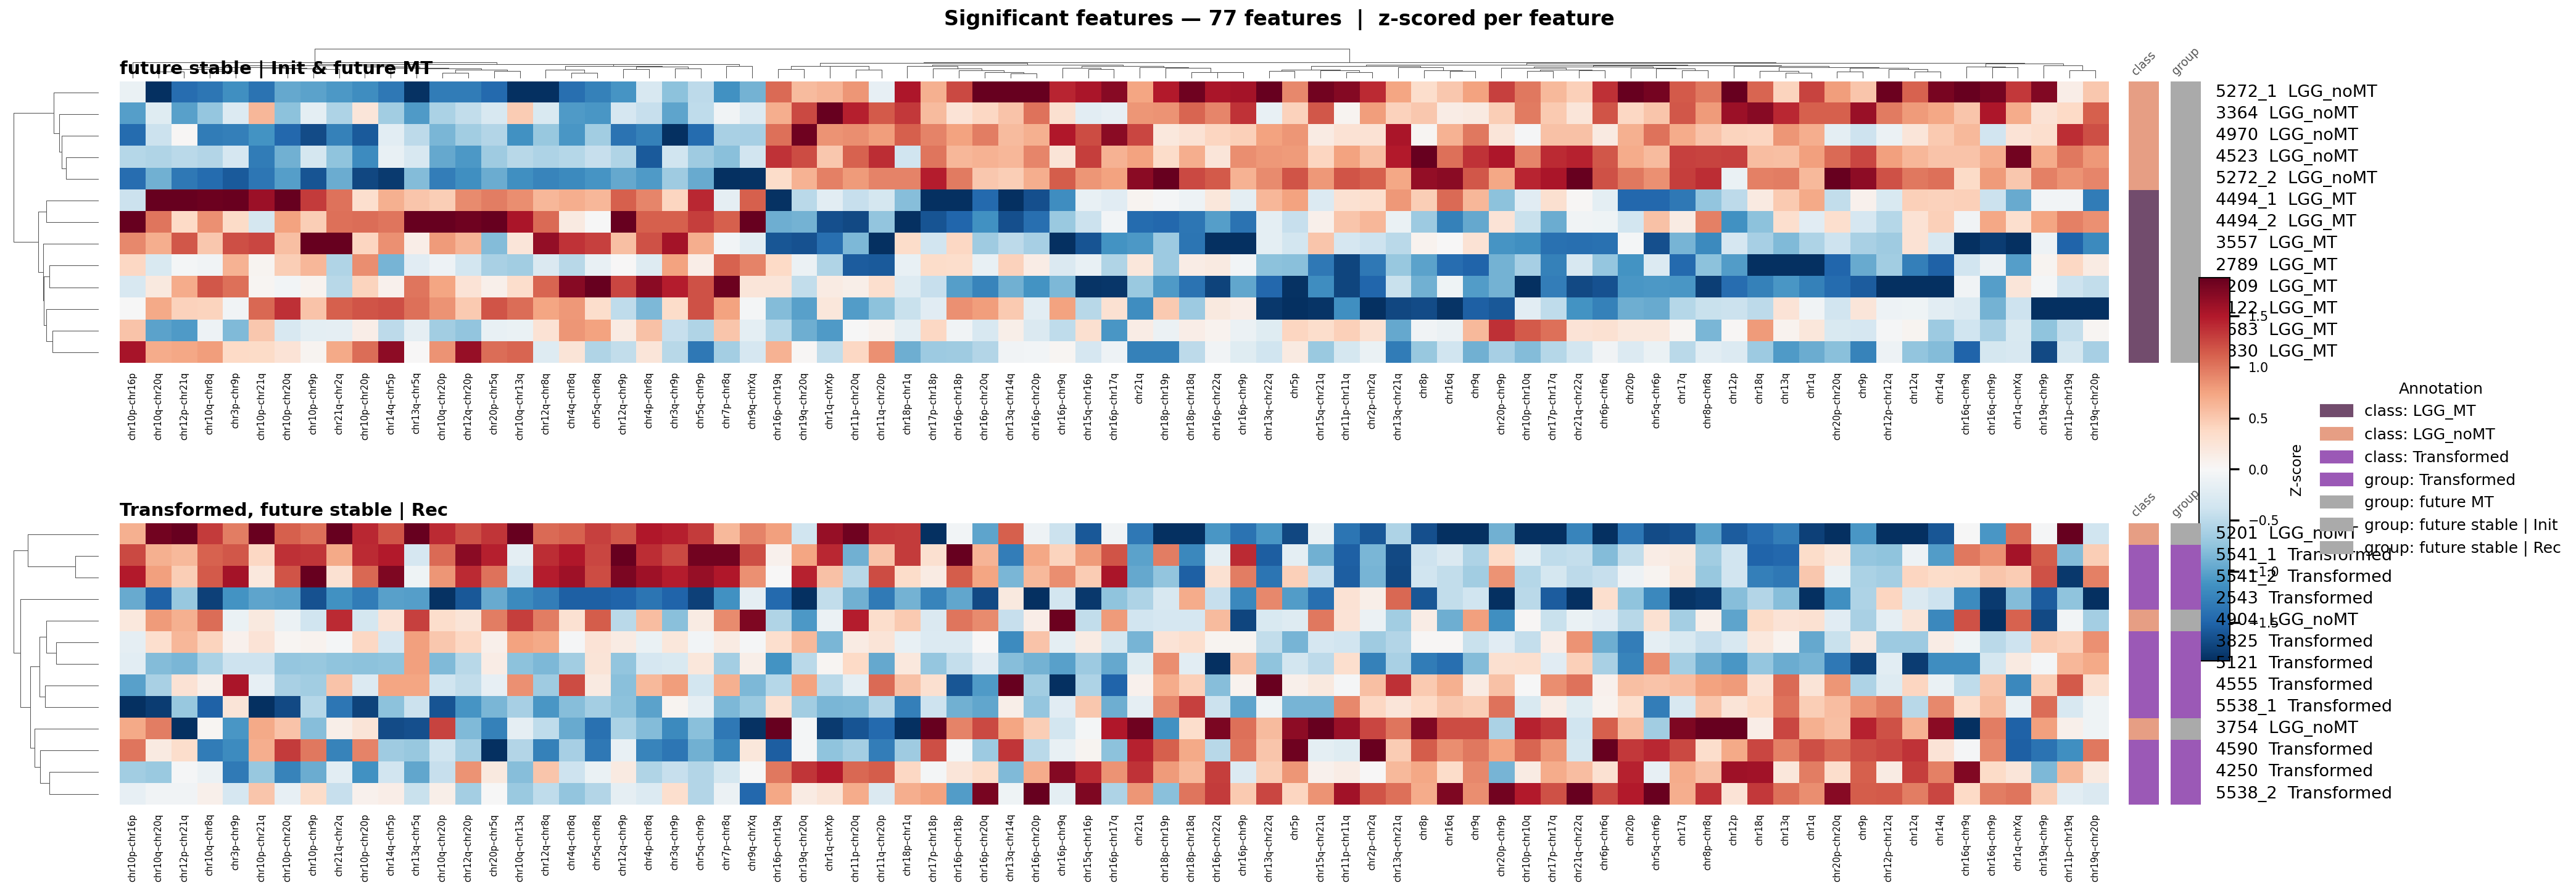

In [23]:
sig_contacts = between.loc[
    between['significant'] & between['feat_type'].isin(['contacts_corr']),
    'feature'
]

mask = (
    contacts_c['state'].isin(
        ['future stable | Init', 'future MT', 'future stable | Rec', 'Transformed']
    )
    & contacts_c['cell_type'].isin(['OPC', 'AC.like', 'OPC.like Prolif.'])
    #                                , 'Oligo. normal', 'Microglia'])
)

feature_col = list(sig_contacts.unique())
n_feat = len(feature_col)
print(n_feat)

col_width_in = MM * 183
gutter_mm    = 25
per_feat_in  = min(0.13, (col_width_in - MM * gutter_mm) / max(n_feat, 1))

fig = plot_annotated_heatmap(
    contacts_c.loc[mask],
    feature_col,
    main_types          = ['future stable | Init', 'future MT'],
    extra_type_keywords = ['Transformed', 'future stable | Rec'],
    figsize_width_per_feature = per_feat_in,
    figsize_base_height       = MM * 68,   # ~55 mm tall panel
    cmap     = 'RdBu_r',
    vmax_pct = 95,
    out_path = f'{OUT_DIR}/Fig3_top_feature_heatmap_MT_noMT.pdf',
)

Saved: figures/Fig3_feature_number_barplot_MT_nonMT.pdf


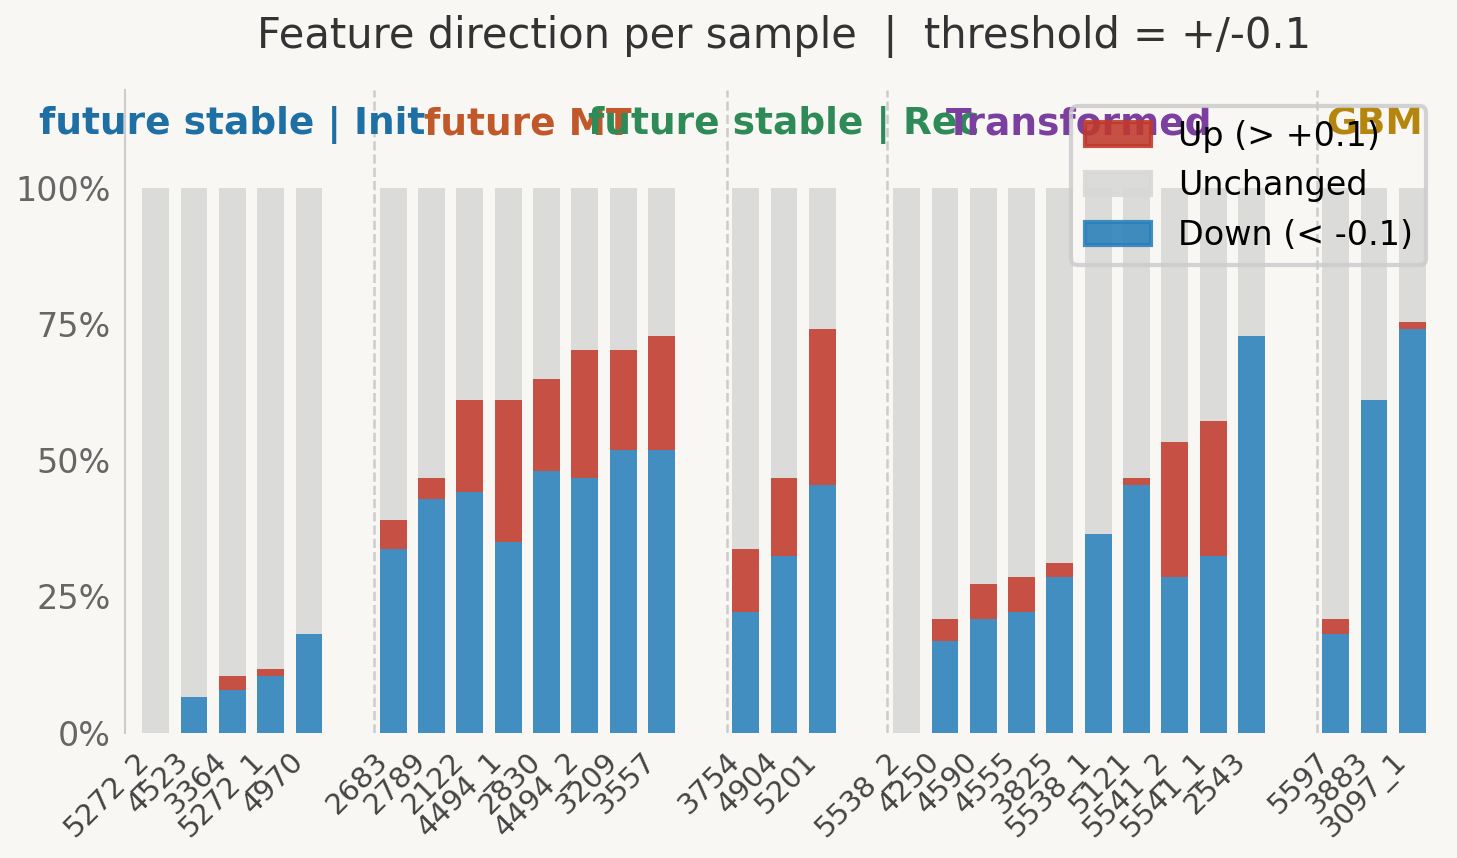

In [24]:
#plot feature number and direction as a brplot
mask = contacts_c['state'].isin(['future stable | Init','future stable | Rec','future MT','Transformed','GBM']) & contacts_c['cell_type'].isin(['OPC','AC.like','OPC.like Prolif.'])#,'Oligo. normal','Microglia'])

tmp = contacts_c.loc[mask,['ROI','state']+feature_col]
tmp = tmp.melt(id_vars=['ROI','state'], var_name='feature').groupby(['ROI','state','feature'])['value'].mean().reset_index()

fig = plot_updown_bars(tmp.pivot_table(index=['ROI','state'], columns='feature', values='value').reset_index().rename_axis('', axis=1),
                       threshold = 0.1, 
                       figsize = (5,3),
                       group_order=['future stable | Init','future MT', 'future stable | Rec', 'Transformed','GBM'],
                       out_path = f'{OUT_DIR}/Fig3_feature_number_barplot_MT_nonMT.pdf'
                      )